# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jhanvi, Riya, Elijah

**Date:** 11/11/2026

16814 -> 16658 rows; missing values left: 0
                               count                           mean  \
sale_date                      16658  2020-07-16 16:32:33.655901184   
sale_price                   16658.0                  461684.477188   
house_square_feet            16658.0                    1882.620483   
attic_finished_square_feet   16658.0                      24.963801   
basement_square_feet         16658.0                     168.726378   
attached_garage_square_feet  16658.0                     364.880058   
detached_garage_square_feet  16658.0                      38.589687   
fireplaces                   16658.0                       0.891704   
stories                      16658.0                       1.561952   
year_built                   16658.0                    1980.405511   
bedrooms                     16658.0                       3.283287   
bathrooms                    16658.0                       2.321467   

                                

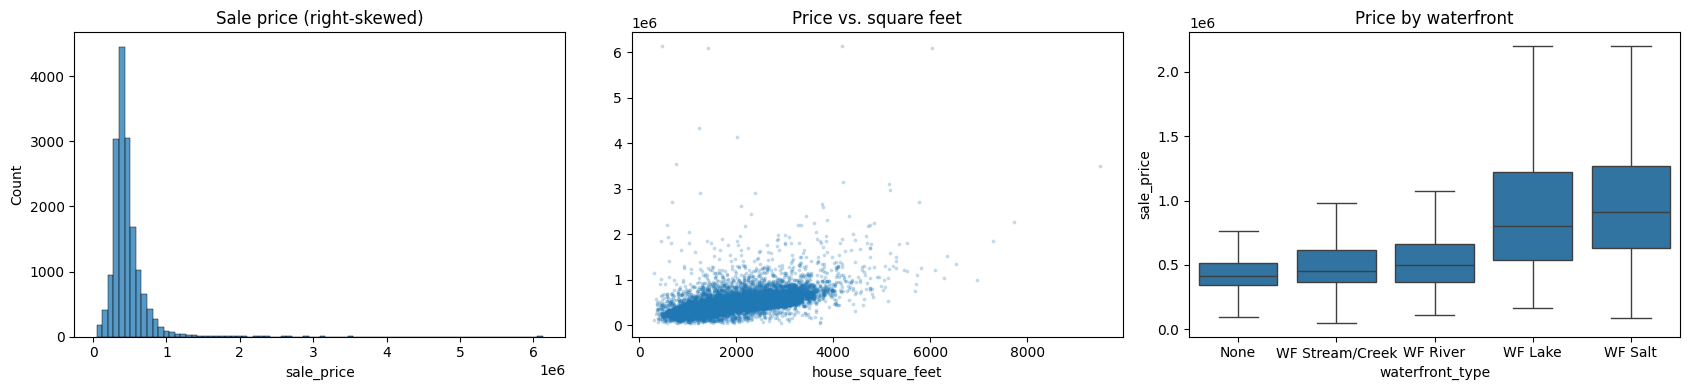

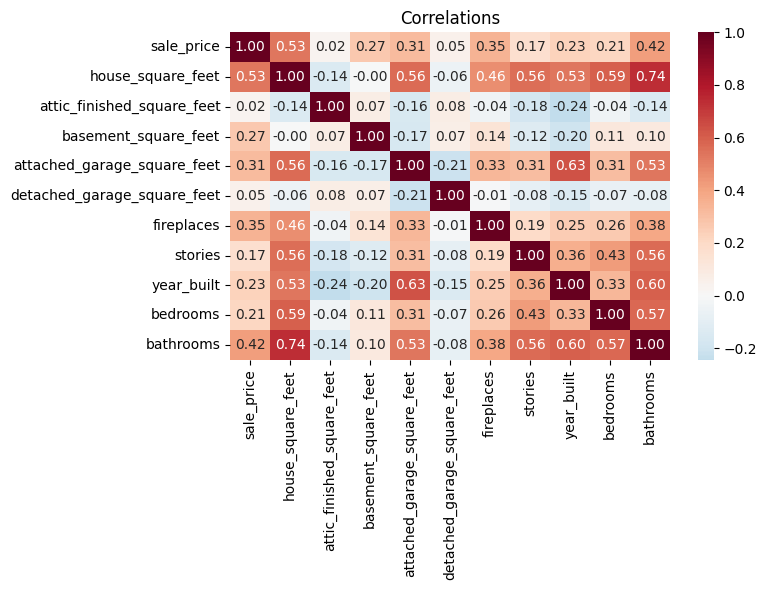

(16658, 31)
train: (13326, 30)  test: (3332, 30)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

URL = "https://raw.githubusercontent.com/elijahschoeniger-cpu/L02-hedonic-pricing/main/data/pierce_county_house_sales.csv"
df_raw = pd.read_csv(URL)

df = df_raw.drop_duplicates().copy()

# Drop impossible / non-market records
df = df[(df["sale_price"] >= 50_000)          # $2k-$50k sales = non-arm's-length transfers
        & (df["house_square_feet"] >= 300)     # 1 sq ft houses etc.
        & (df["stories"] > 0)
        & (df["bedrooms"] <= 12)]              # one 25-bedroom record

# NaN here not missing
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("No View")

# Only ~10 rows missing these; drop them
df = df.dropna(subset=["hvac_description", "exterior", "interior", "roof_cover"])

# Fix inconsistent labels
df["hvac_description"] = df["hvac_description"].replace(
    {"Floor Wall Furnace": "Floor/Wall Furnace", "Electric": "Electric Baseboard"})

df = df[df["bathrooms"] > 0]

df["sale_date"] = pd.to_datetime(df["sale_date"])
df = df.reset_index(drop=True)
print(f"{len(df_raw)} -> {len(df)} rows; missing values left: {df.isna().sum().sum()}")

num_cols = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
            "attached_garage_square_feet", "detached_garage_square_feet",
            "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"]

print(df.describe().T)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df["sale_price"], bins=80, ax=ax[0]).set_title("Sale price (right-skewed)")
ax[1].scatter(df["house_square_feet"], df["sale_price"], s=3, alpha=0.2)
ax[1].set(title="Price vs. square feet", xlabel="house_square_feet")
order = df.groupby("waterfront_type")["sale_price"].median().sort_values().index
sns.boxplot(data=df, x="waterfront_type", y="sale_price", order=order, showfliers=False, ax=ax[2])
ax[2].set_title("Price by waterfront")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[["sale_price"] + num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlations"); plt.tight_layout(); plt.show()

#Price is heavily right skewed, square footage footage is strongest r=0.53, followed by bathrooms.


#Q2
X = df.copy()
X["sale_month"] = X["sale_date"].dt.month

# Ordered view grades -> 0..8
view_order = ["No View", "View Lim -", "View Lim", "View Lim +", "View Avg",
              "View Avg +", "View Good", "View Good +", "View V-Good"]
X["view_score"] = X["view_quality"].map({v: i for i, v in enumerate(view_order)})

# Near-constant columns -> one binary flag each
X["interior_drywall"] = (X["interior"] == "Drywall").astype(int)
X["sewer_installed"] = (X["utility_sewer"] == "SEWER/SEPTIC INSTALLED").astype(int)

# Group rare levels
X["exterior"] = X["exterior"].replace({"Masonry Common Brick": "Masonry", "Masonry Concrete Block": "Masonry"})
X["exterior"] = X["exterior"].where(X["exterior"].isin(["Frame Siding", "Frame Vinyl", "Masonry", "Frame Stucco"]), "Other")
X["hvac_description"] = X["hvac_description"].where(
    X["hvac_description"].isin(["Forced Air", "Electric Baseboard", "Heat Pump", "Warm and Cool Air Zone"]), "Other")
X["roof_cover"] = X["roof_cover"].replace({"Formed Seam Metal": "Metal", "Preformed Metal": "Metal"})

X = X.drop(columns=["sale_date", "view_quality", "interior", "utility_sewer"])

# One-hot encode with most common level as the dropped baseline
for c, base in {"exterior": "Frame Siding", "hvac_description": "Forced Air",
                "roof_cover": "Composition Shingle", "waterfront_type": "None"}.items():
    X[c] = pd.Categorical(X[c], categories=[base] + sorted(set(X[c]) - {base}))
X = pd.get_dummies(X, columns=["exterior", "hvac_description", "roof_cover", "waterfront_type"],
                   drop_first=True, dtype=int)
X.columns = X.columns.str.replace(r"[ /]+", "_", regex=True)

print(X.shape)
X.head()

#sale_date goes to sale_month, view_quality


#Q3
y = X.pop("sale_price")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)





In [3]:
# question 4

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

features1 = ["house_square_feet", "bedrooms", "bathrooms"]

features2 = [c for c in num_cols if c in X_train.columns]

features3 = list(X_train.columns)

models = [features1, features2, features3]

for i, features in enumerate(models):

    model = LinearRegression()
    model.fit(X_train[features], y_train)

    train_pred = model.predict(X_train[features])
    test_pred = model.predict(X_test[features])

    print(f"\nModel {i+1}")
    print("Training RMSE:", mean_squared_error(y_train, train_pred)**0.5)
    print("Testing RMSE:", mean_squared_error(y_test, test_pred)**0.5)
    print("Training R2:", r2_score(y_train, train_pred))
    print("Testing R2:", r2_score(y_test, test_pred))

# I made three linear regression models using different combinations of predictors.
# Model 1 included basic house characteristics such as square footage, bedrooms, and bathrooms.
# Model 2 had all numeric variables, and Model 3 included all available variables, including categorical variables.
# After comparing the training and testing RMSE and R^2 values, Model 3 performed the best.
# Model 3 had the lowest testing RMSE of 182,745 and the highest testing R^2 of 0.501.
# The training and testing results were relatively close, which might mean that the model generalizes well to unseen data.


Model 1
Training RMSE: 187493.74044099008
Testing RMSE: 219502.9305618803
Training R2: 0.31486270056966537
Testing R2: 0.2795129166401483

Model 2
Training RMSE: 170476.4657364708
Testing RMSE: 206331.98905336577
Training R2: 0.43358736659252406
Testing R2: 0.3633823379850667

Model 3
Training RMSE: 149859.36860516804
Testing RMSE: 182744.53640529024
Training R2: 0.5623047212604799
Testing R2: 0.5006163069625785


<Figure size 1500x1200 with 0 Axes>

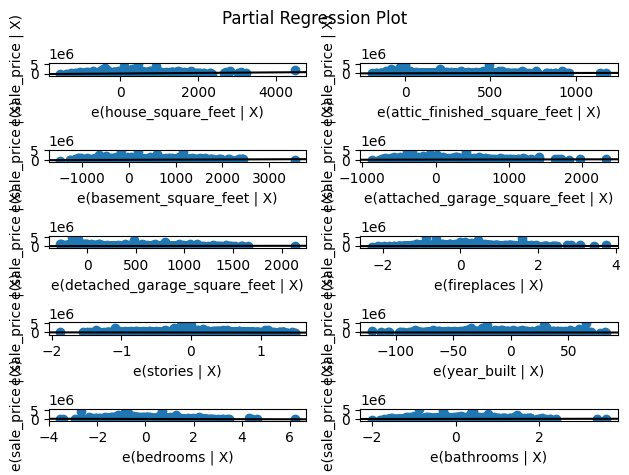

In [4]:
# question 5


import statsmodels.api as sm
import matplotlib.pyplot as plt

X_ols = sm.add_constant(X_train[features3])

model = sm.OLS(y_train, X_ols).fit()

plt.figure(figsize=(15, 12))

fig = sm.graphics.plot_partregress_grid(
    model,
    exog_idx=num_cols)

plt.tight_layout()
plt.show()

# The partial regression plots show the relationship between each numeric variable and sale price,  controlling for the other variables in the model.
# Most of the variables have mostly linear relationships, although there is some scatter in the data.
# I did not notice any significant nonlinear patterns or obvious curves in the plots.
# There are also some outliers that may affect the relationships.
# Overall, the plots show that a simple linear regression model is a reasonable starting point for modeling house sale prices, but it might not capture every relationship perfectly.

In [5]:
# Question 6


train = X_train.copy()
test = X_test.copy()


for data in [train, test]:
   data["sqft2"] = data["house_square_feet"] ** 2
   data["bath2"] = data["bathrooms"] ** 2
   data["sqft_bath"] = data["house_square_feet"] * data["bathrooms"]
   data["sqft_bed"] = data["house_square_feet"] * data["bedrooms"]


# train model
model6 = LinearRegression()
model6.fit(train, y_train)


# predictions (train/test)
pred_train = model6.predict(train)
pred_test = model6.predict(test)


print("Nodel 6\n")
print("Train RMSE:", mean_squared_error(y_train, pred_train)**0.5)
print("Train R2:", r2_score(y_train, pred_train))
print("\nTest RMSE:", mean_squared_error(y_test, pred_test)**0.5)
print("Test R2:", r2_score(y_test, pred_test))


# Question 7


# For this lab, we cleaned the data, performed EDA, and built regression models.
# Out of the simpler models, model 3 performed best with the test RSME at 182,745 and a R^2 value of 0.5.
# The more complex model improved performance by reducing test RMSE and slightly increasing test R^2.
# However, the test R^2 for this model was actually lower than its respective training R^2, potentially indicative of overfitting.
# This shows that more complex models can improve performance,
# but we should compare test results with training results



# Question 8


from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)


# Train  model
lasso = LassoCV(cv=5, max_iter=20000, random_state=42)
lasso.fit(train_scaled, y_train)


pred_train = lasso.predict(train_scaled)
pred_test = lasso.predict(test_scaled)


print("Lasso Model\n")
print("Train RMSE:", mean_squared_error(y_train, pred_train)**0.5)
print("Train R2:", r2_score(y_train, pred_train))
print("\nTest RMSE:", mean_squared_error(y_test, pred_test)**0.5)
print("Test R2:", r2_score(y_test, pred_test))


selected = train.columns[lasso.coef_ != 0]
print("\nSelected Features:")
print(selected.tolist())





Nodel 6

Train RMSE: 149114.5954472249
Train R2: 0.5666444386749805

Test RMSE: 180060.3180497248
Test R2: 0.5151788252913141
Lasso Model

Train RMSE: 149178.8756852479
Train R2: 0.5662707367893347

Test RMSE: 180459.0157871379
Test R2: 0.5130294221233204

Selected Features:
['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'sale_month', 'view_score', 'interior_drywall', 'exterior_Frame_Stucco', 'exterior_Frame_Vinyl', 'exterior_Masonry', 'exterior_Other', 'hvac_description_Electric_Baseboard', 'hvac_description_Heat_Pump', 'hvac_description_Other', 'hvac_description_Warm_and_Cool_Air_Zone', 'roof_cover_Built_Up_Rock', 'roof_cover_Concrete_Tile', 'roof_cover_Metal', 'roof_cover_Wood_Shake', 'waterfront_type_WF_Lake', 'waterfront_type_WF_River', 'waterfront_type_WF_Salt', 'waterfront_type_WF_Stream_Creek', 'sqft2', 'sqft_bath', 'sqft_bed']


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]